# Task 03: Predicting Term-Deposit Subscriptions with a Decision Tree

<a href="https://colab.research.google.com/github/alhaddad-a/PRODIGY_DS/blob/main/Task_03_Bank_Marketing_Decision_Tree/Task3_Bank_Marketing_Decision_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Prodigy InfoTech Data Science Internship

Task: build a decision tree classifier to predict whether a customer will purchase a product or service based on their demographic and behavioral data.

Data: UCI Bank Marketing dataset (`bank-additional-full.csv`): 41,188 phone calls made by a Portuguese bank between May 2008 and November 2010. Source: https://archive.ics.uci.edu/dataset/222/bank+marketing

## 1. Problem statement

A bank runs phone campaigns to sell a **term deposit**. Most calls fail (only about 11% of customers say yes), and every call costs agent time.

**Business question:** before calling, can we rank customers by how likely they are to subscribe, so agents call the most promising ones first?

- **Target:** `y` = yes / no (subscribed to a term deposit)
- **Model:** a decision tree, because the bank can read and explain its rules
- **Success:** better than random at finding buyers, measured by ROC-AUC, precision/recall for the "yes" class, and **lift** (how many more buyers we reach by calling the top-ranked customers)

**Important design decision: no `duration`.** The dataset includes the length of the call. It predicts the outcome very well, but it is only known **after** the call ends, and a 0-second call is always a "no". Using it would be data leakage: the model would look great in testing and be useless in practice. I show its effect in section 7, then leave it out.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (roc_auc_score, average_precision_score, classification_report,
                             confusion_matrix, roc_curve, precision_recall_curve)

os.makedirs("images", exist_ok=True)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9aa0a6"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

def save(fig, name):
    fig.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")

def pct(ax, axis="y"):
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(mticker.PercentFormatter(1.0))

## 2. Load data

In [2]:
url = "https://raw.githubusercontent.com/Prodigy-InfoTech/data-science-datasets/main/Task%203/bank-additional/bank-additional-full.csv"
raw = pd.read_csv(url, sep=";")
print(raw.shape)
raw.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


| Group | Columns |
|---|---|
| Customer | age, job, marital, education, default (credit in default?), housing (housing loan?), loan (personal loan?) |
| Current campaign | contact (cellular/telephone), month, day_of_week, campaign (calls this campaign), duration (call length, **excluded**) |
| Past campaigns | pdays (days since last contact, 999 = never), previous (past contacts), poutcome (past outcome) |
| Economy (quarterly/monthly) | emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m (3-month interest rate), nr.employed |
| Target | y: subscribed to a term deposit |

## 3. Data quality

In [3]:
print("Missing values (NaN):", raw.isna().sum().sum())
print("Duplicate rows:", raw.duplicated().sum())
cat_cols = raw.select_dtypes(exclude="number").columns.drop("y")
unknown = (raw[cat_cols] == "unknown").sum()
print("\n'unknown' values per column:")
print(unknown[unknown > 0])
print(f"\npdays == 999 (never contacted before): {(raw['pdays'] == 999).mean():.1%}")

Missing values (NaN): 0
Duplicate rows: 12

'unknown' values per column:
job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64

pdays == 999 (never contacted before): 96.3%


- There are no NaNs, but missing values are coded as the text **"unknown"**. I keep "unknown" as its own category instead of dropping rows. For `default`, "unknown" may itself be informative (people who don't disclose).
- **12 exact duplicate rows** are dropped.
- `pdays = 999` means "never contacted before" (96% of rows). It is a code, not a number of days, so I add a flag `contacted_before` and set pdays to `-1` for those rows, so a tree split like `pdays <= -0.5` simply means "never contacted before".

In [4]:
df = raw.drop_duplicates().copy()
df["y"] = (df["y"] == "yes").astype(int)
df["contacted_before"] = (df["pdays"] != 999).astype(int)
df.loc[df["pdays"] == 999, "pdays"] = -1
print(df.shape)
print(f"Subscription rate: {df['y'].mean():.1%}")

(41176, 22)
Subscription rate: 11.3%


## 4. Exploratory analysis: who subscribes?

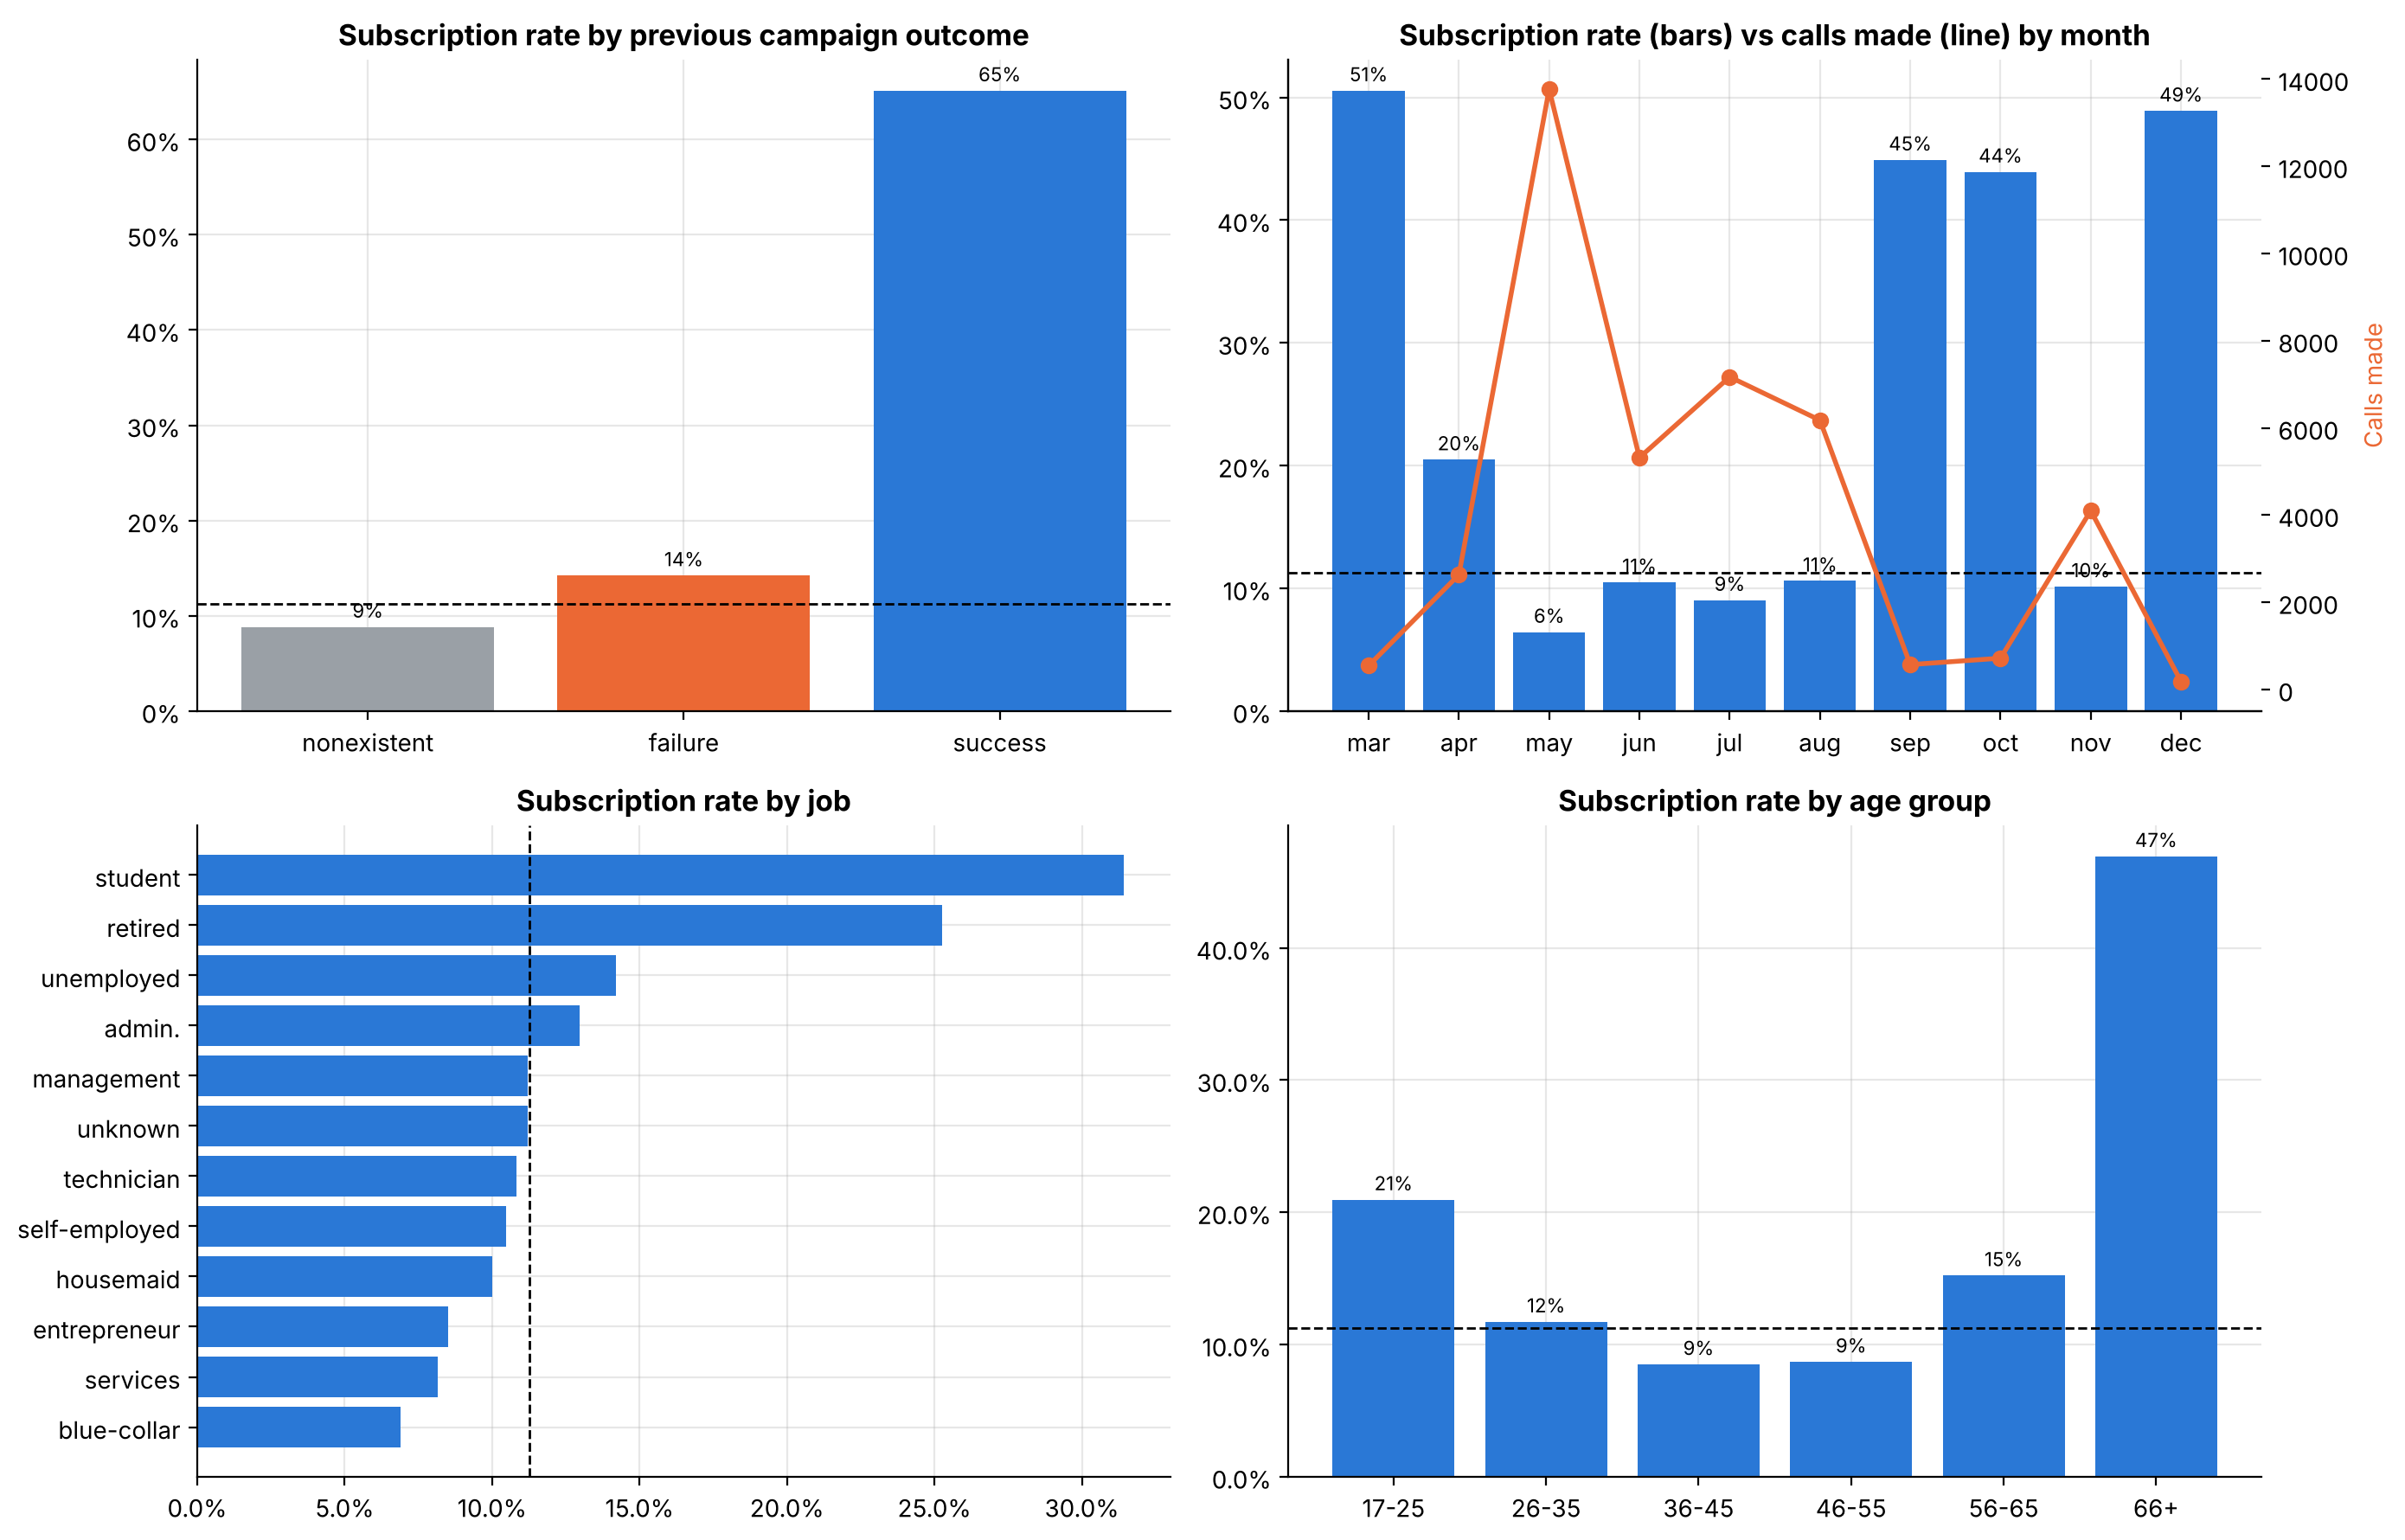

In [5]:
def rate(col, order=None):
    r = df.groupby(col)["y"].agg(["mean", "size"])
    return r.loc[order] if order is not None else r.sort_values("mean")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

r = rate("poutcome", ["nonexistent", "failure", "success"])
axes[0, 0].bar(r.index, r["mean"], color=[GREY, ORANGE, BLUE])
axes[0, 0].set_title("Subscription rate by previous campaign outcome")

months = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
r = rate("month", months)
ax = axes[0, 1]
ax.bar(r.index, r["mean"], color=BLUE)
ax2 = ax.twinx()
ax2.plot(r.index, r["size"], color=ORANGE, marker="o", lw=2)
ax2.set_ylabel("Calls made", color=ORANGE)
ax2.grid(False); ax2.spines["top"].set_visible(False)
ax.set_title("Subscription rate (bars) vs calls made (line) by month")

r = rate("job")
axes[1, 0].barh(r.index, r["mean"], color=BLUE)
pct(axes[1, 0], "x")
axes[1, 0].set_title("Subscription rate by job")

df["age_group"] = pd.cut(df["age"], [16, 25, 35, 45, 55, 65, 100],
                         labels=["17-25", "26-35", "36-45", "46-55", "56-65", "66+"])
r = df.groupby("age_group", observed=True)["y"].mean()
axes[1, 1].bar(r.index.astype(str), r.values, color=BLUE)
axes[1, 1].set_title("Subscription rate by age group")

for ax in [axes[0, 0], axes[0, 1], axes[1, 1]]:
    pct(ax)
    for c in ax.containers:
        ax.bar_label(c, labels=[f"{v:.0%}" for v in c.datavalues], fontsize=8, padding=2)
for ax in axes.flat:
    ax.axhline(df["y"].mean(), color="black", ls="--", lw=1) if ax is not axes[1, 0] else ax.axvline(df["y"].mean(), color="black", ls="--", lw=1)
fig.tight_layout()
save(fig, "01_subscription_rates")
plt.show()

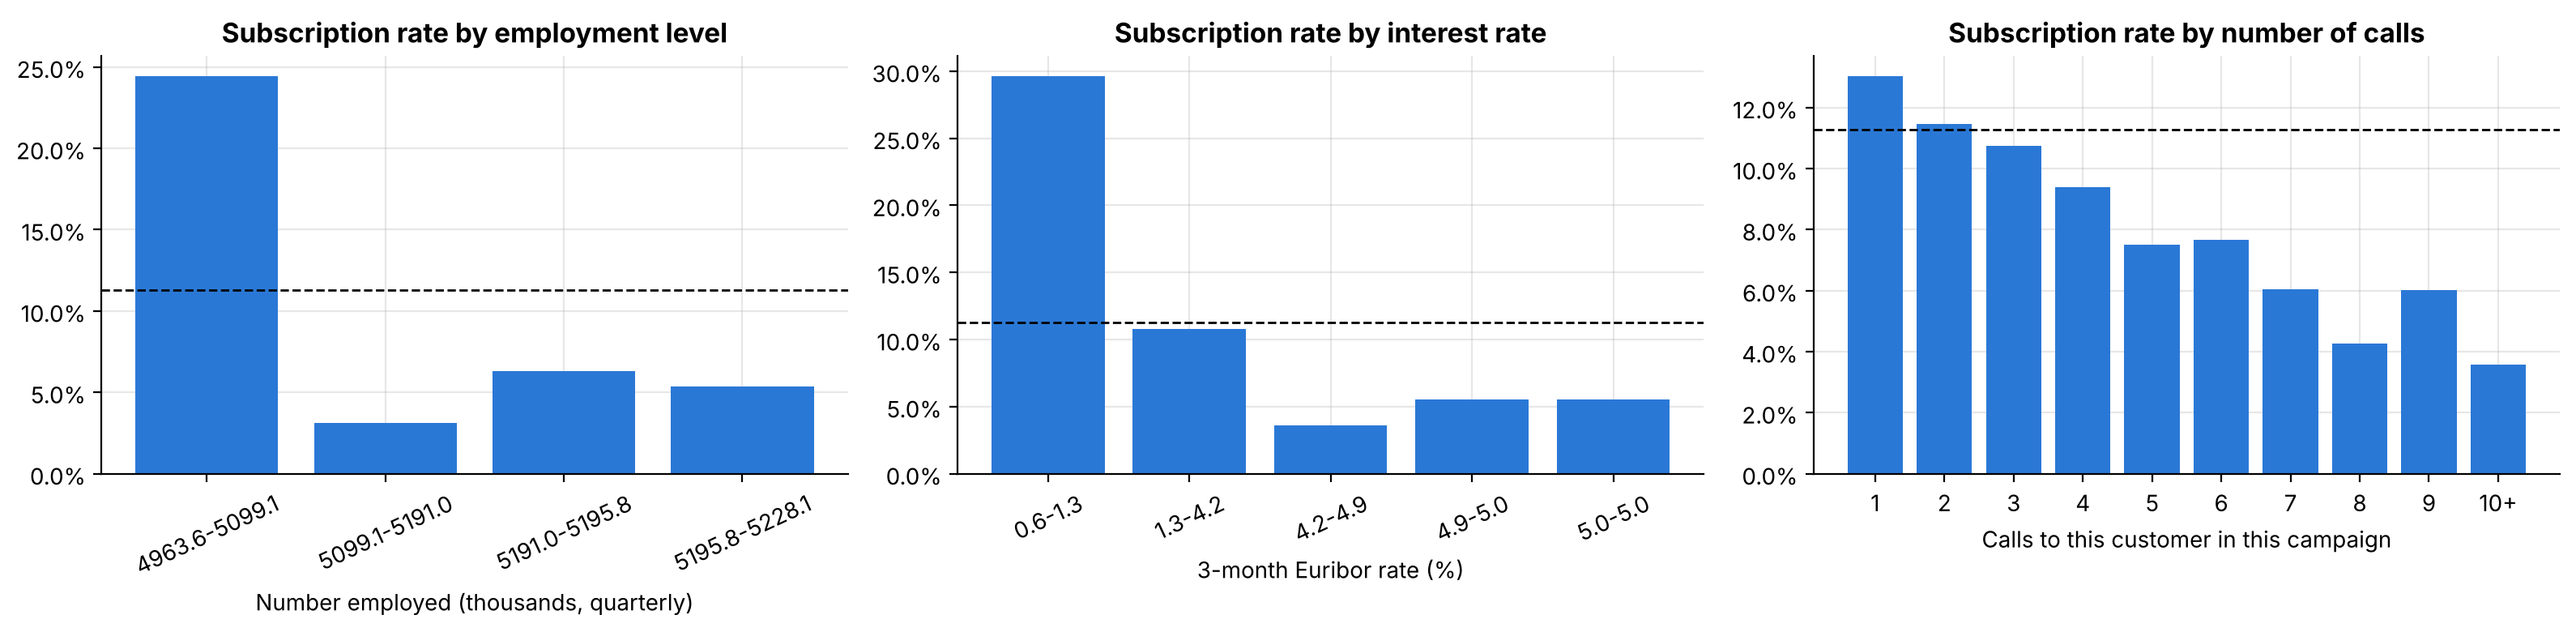

contact
cellular     0.147
telephone    0.052
Name: y, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, label in zip(axes, ["nr.employed", "euribor3m", "campaign"],
                          ["Number employed (thousands, quarterly)", "3-month Euribor rate (%)", "Calls to this customer in this campaign"]):
    if col == "campaign":
        g = df.assign(b=df[col].clip(upper=10)).groupby("b")["y"].mean()
        ax.bar(g.index.astype(int).astype(str).str.replace("10", "10+"), g.values, color=BLUE)
    else:
        g = df.groupby(pd.qcut(df[col], 5, duplicates="drop"), observed=True)["y"].mean()
        ax.bar([f"{i.left:.1f}-{i.right:.1f}" for i in g.index], g.values, color=BLUE)
        ax.tick_params(axis="x", rotation=25)
    pct(ax)
    ax.set_xlabel(label)
    ax.axhline(df["y"].mean(), color="black", ls="--", lw=1)
axes[0].set_title("Subscription rate by employment level")
axes[1].set_title("Subscription rate by interest rate")
axes[2].set_title("Subscription rate by number of calls")
fig.tight_layout()
save(fig, "02_economy_and_calls")
plt.show()
print(df.groupby("contact")["y"].mean().round(3))

**What the data shows**

- **Past success is the strongest single signal:** customers who said yes in a previous campaign subscribe about 65% of the time, vs about 9% for customers never contacted before.
- **Timing matters more than demographics.** May had by far the most calls but the lowest success rate (about 6%). March, September, October and December had few calls but around 45-50% success.
- **The economy matters.** Subscription rates are much higher when employment (`nr.employed`) and interest rates (`euribor3m`) were low (2009-2010, after the financial crisis). These features describe *when* the call happened.
- **Students (31%) and retirees (25%)** subscribe most often, and customers **over 65 subscribe at 47%**. Blue-collar and services workers are lowest (7-8%).
- **Calling the same person many times doesn't help.** The rate falls steadily with each extra call in a campaign.
- Calls to **mobile phones** (cellular) succeed about 3 times as often as landline calls.

## 5. Modelling

Steps:
1. One-hot encode categorical columns (trees need numbers).
2. Split 80/20 into train and test sets, **stratified** so both have about 11% "yes".
3. Show why an unrestricted tree is a bad idea (overfitting).
4. Tune depth and minimum leaf size with 5-fold cross-validation on the training set only.
5. Use `class_weight="balanced"` so the tree pays attention to the rare "yes" class.

In [7]:
features = df.drop(columns=["y", "duration", "age_group"])
X = pd.get_dummies(features, drop_first=False).astype(float)
y = df["y"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Train: {X_train.shape}, Test: {X_test.shape}, features: {X.shape[1]}")
print(f"Yes rate train {y_train.mean():.1%}, test {y_test.mean():.1%}")

# Baseline: always predict "no"
print(f"\nBaseline accuracy (always 'no'): {1 - y_test.mean():.1%}  <- why accuracy is a bad metric here")

Train: (32940, 63), Test: (8236, 63), features: 63
Yes rate train 11.3%, test 11.3%

Baseline accuracy (always 'no'): 88.7%  <- why accuracy is a bad metric here


Unrestricted tree: depth 34, 4,988 leaves
  ROC-AUC train 1.000  vs test 0.627


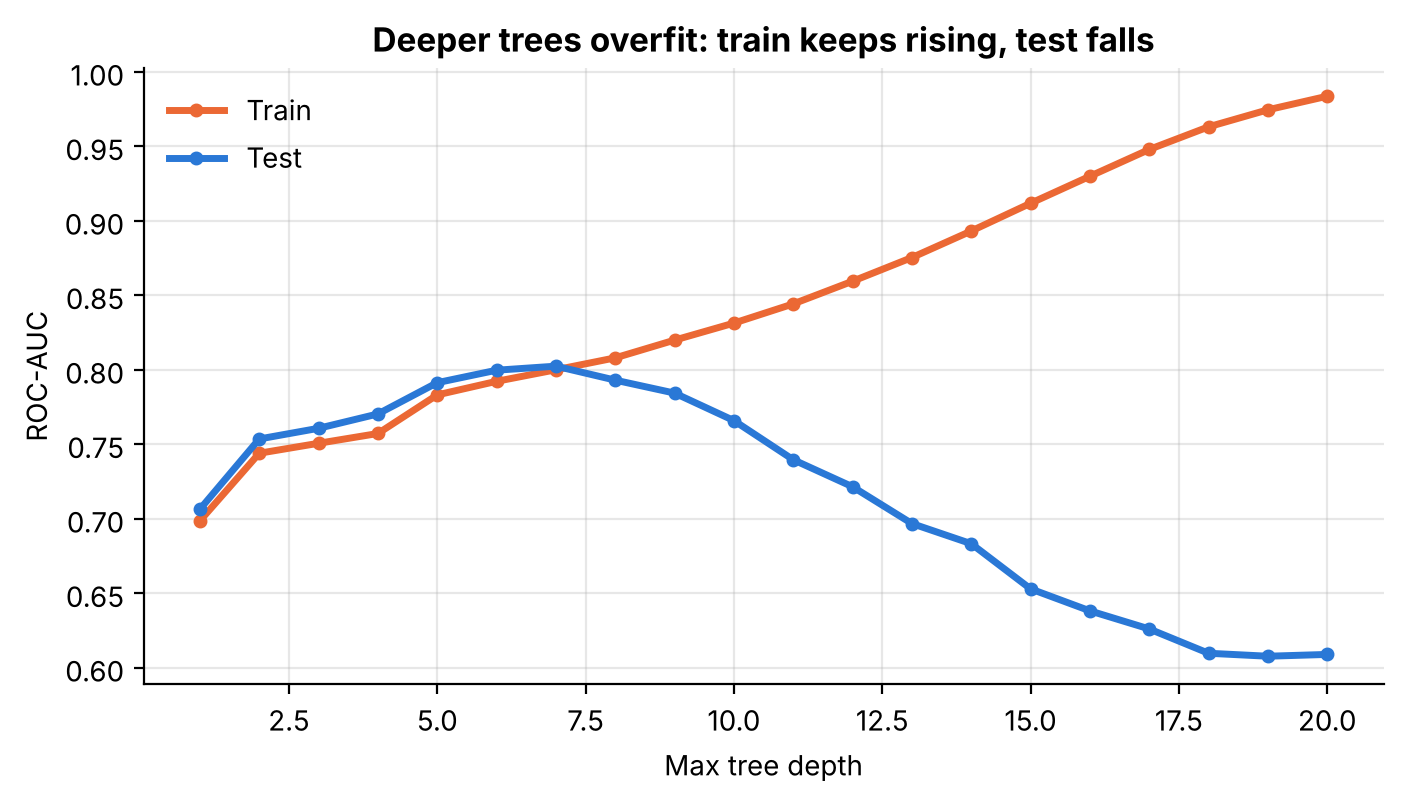

In [8]:
# An unrestricted tree memorizes the training data
full = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print(f"Unrestricted tree: depth {full.get_depth()}, {full.get_n_leaves():,} leaves")
print(f"  ROC-AUC train {roc_auc_score(y_train, full.predict_proba(X_train)[:, 1]):.3f}"
      f"  vs test {roc_auc_score(y_test, full.predict_proba(X_test)[:, 1]):.3f}")

depths = range(1, 21)
tr, te = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    tr.append(roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]))
    te.append(roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depths, tr, color=ORANGE, lw=2.5, marker="o", ms=4, label="Train")
ax.plot(depths, te, color=BLUE, lw=2.5, marker="o", ms=4, label="Test")
ax.set_xlabel("Max tree depth"); ax.set_ylabel("ROC-AUC")
ax.legend(frameon=False)
ax.set_title("Deeper trees overfit: train keeps rising, test falls")
save(fig, "03_overfitting_depth")
plt.show()

In [9]:
grid = {"max_depth": [3, 4, 5, 6, 8, 10, 12],
        "min_samples_leaf": [20, 50, 100, 200, 400],
        "criterion": ["gini", "entropy"]}
search = GridSearchCV(DecisionTreeClassifier(class_weight="balanced", random_state=42), grid,
                      scoring="roc_auc", cv=StratifiedKFold(5, shuffle=True, random_state=42), n_jobs=-1)
search.fit(X_train, y_train)
tree = search.best_estimator_
print("Best parameters:", search.best_params_)
print(f"Cross-validated ROC-AUC: {search.best_score_:.3f}")
print(f"Tree size: depth {tree.get_depth()}, {tree.get_n_leaves()} leaves")

Best parameters: {'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 200}
Cross-validated ROC-AUC: 0.786
Tree size: depth 12, 97 leaves


## 6. Evaluation on the test set

In [10]:
proba = tree.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
auc = roc_auc_score(y_test, proba)
ap = average_precision_score(y_test, proba)
print(f"ROC-AUC:           {auc:.3f}")
print(f"Average precision: {ap:.3f}  (random = {y_test.mean():.3f})")
print()
print(classification_report(y_test, pred, target_names=["No", "Yes"], digits=3))

ROC-AUC:           0.804
Average precision: 0.467  (random = 0.113)

              precision    recall  f1-score   support

          No      0.949     0.867     0.906      7308
         Yes      0.376     0.634     0.472       928

    accuracy                          0.840      8236
   macro avg      0.663     0.750     0.689      8236
weighted avg      0.885     0.840     0.857      8236



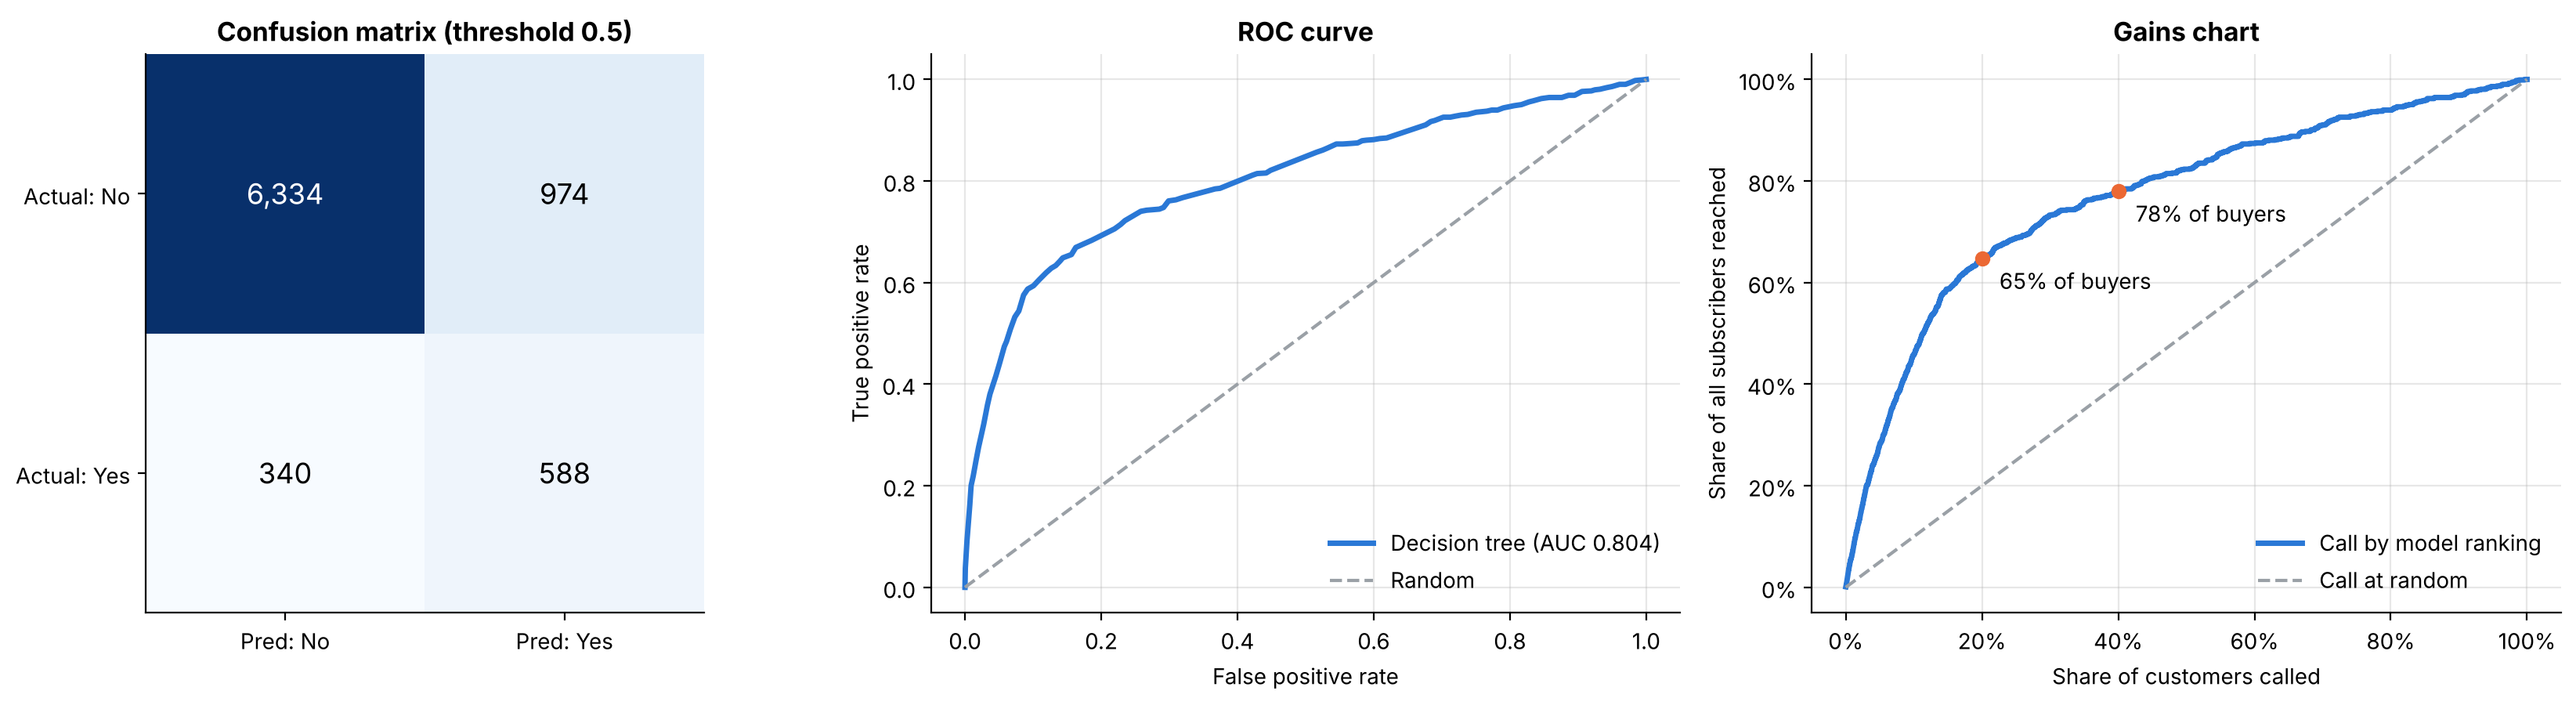

Calling the top 10%: reaches 46% of subscribers (lift 4.6x vs random), conversion 52%
Calling the top 20%: reaches 65% of subscribers (lift 3.2x vs random), conversion 36%
Calling the top 30%: reaches 73% of subscribers (lift 2.4x vs random), conversion 28%


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

cm = confusion_matrix(y_test, pred)
axes[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=13,
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
axes[0].set_xticks([0, 1], ["Pred: No", "Pred: Yes"]); axes[0].set_yticks([0, 1], ["Actual: No", "Actual: Yes"])
axes[0].grid(False)
axes[0].set_title("Confusion matrix (threshold 0.5)")

fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, color=BLUE, lw=2.5, label=f"Decision tree (AUC {auc:.3f})")
axes[1].plot([0, 1], [0, 1], color=GREY, ls="--", label="Random")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].legend(frameon=False, loc="lower right")
axes[1].set_title("ROC curve")

# Lift / gains: call customers in order of predicted probability
order = np.argsort(-proba)
captured = np.cumsum(y_test[order]) / y_test.sum()
called = np.arange(1, len(order) + 1) / len(order)
axes[2].plot(called, captured, color=BLUE, lw=2.5, label="Call by model ranking")
axes[2].plot([0, 1], [0, 1], color=GREY, ls="--", label="Call at random")
for share in [0.2, 0.4]:
    k = int(share * len(order))
    axes[2].scatter(share, captured[k - 1], color=ORANGE, zorder=3)
    axes[2].annotate(f"{captured[k-1]:.0%} of buyers", (share, captured[k - 1]), xytext=(8, -14), textcoords="offset points")
pct(axes[2]); pct(axes[2], "x")
axes[2].set_xlabel("Share of customers called"); axes[2].set_ylabel("Share of all subscribers reached")
axes[2].legend(frameon=False, loc="lower right")
axes[2].set_title("Gains chart")
fig.tight_layout()
save(fig, "04_evaluation")
plt.show()

for share in [0.1, 0.2, 0.3]:
    k = int(share * len(order))
    print(f"Calling the top {share:.0%}: reaches {captured[k-1]:.0%} of subscribers "
          f"(lift {captured[k-1]/share:.1f}x vs random), conversion {y_test[order][:k].mean():.0%}")

**Reading the results**

- Accuracy alone is misleading: always saying "no" is already about 89% accurate. The useful question is how well the model **ranks** customers.
- The **gains chart** is the business result: calling customers in the order the tree ranks them reaches several times more subscribers than calling at random for the same number of calls.
- The 0.5 threshold with balanced class weights favors recall: the model catches most buyers but also flags many non-buyers. The bank can pick a threshold based on how many calls agents can make.

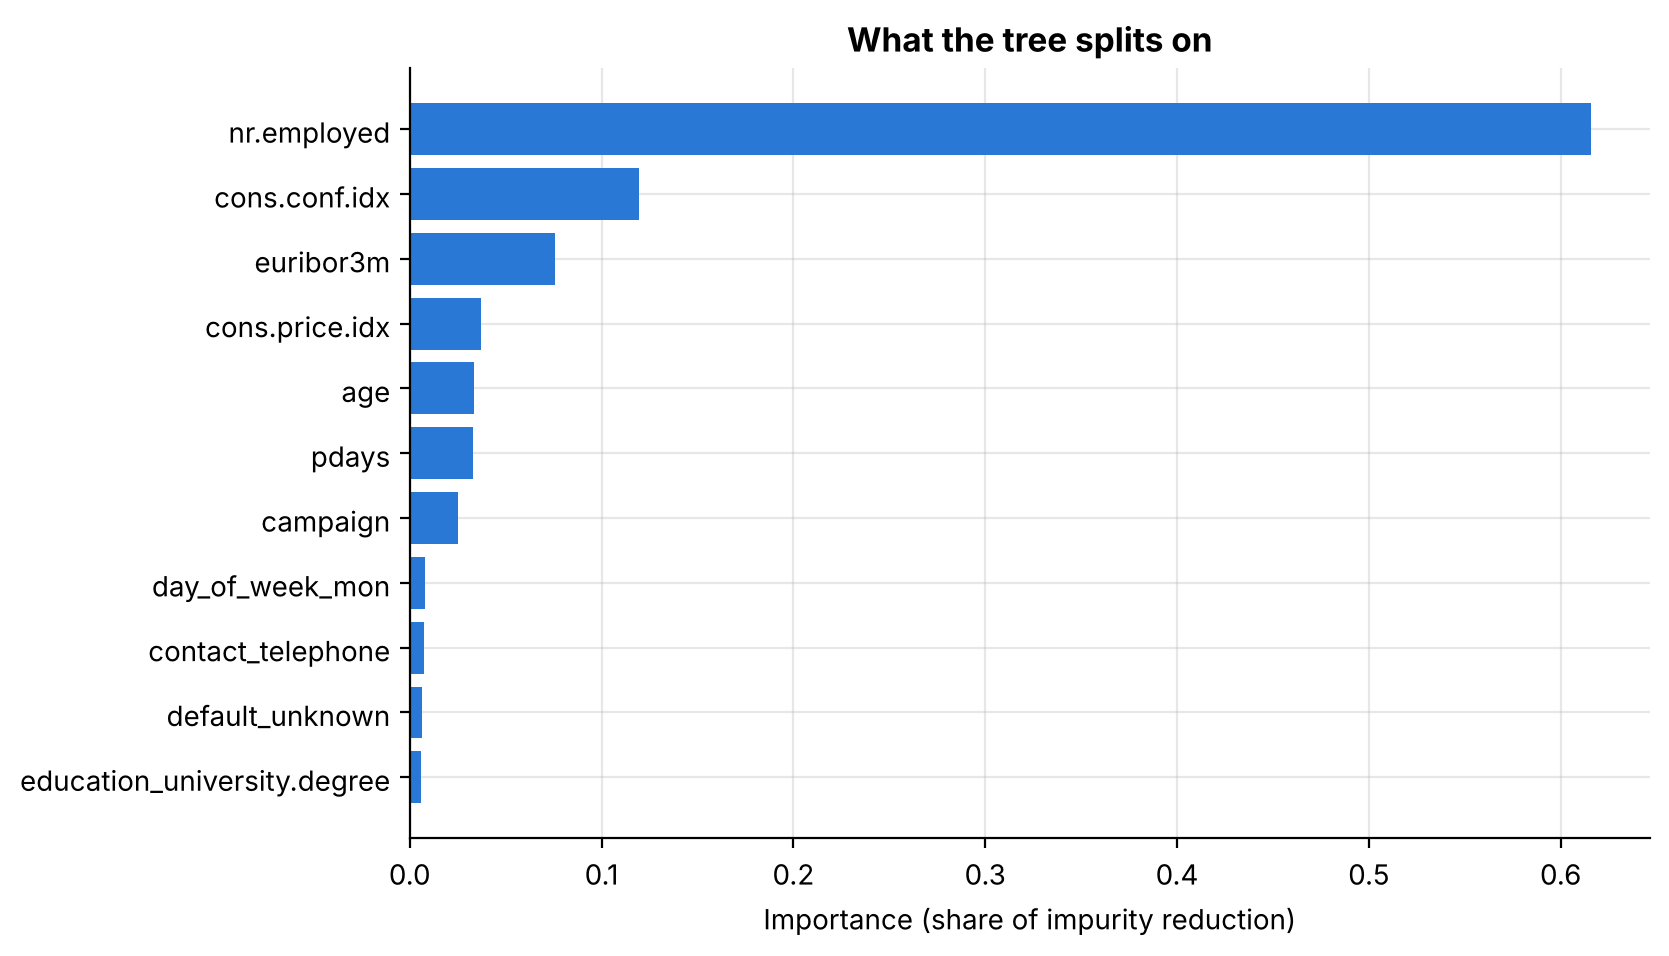

nr.employed          0.616
cons.conf.idx        0.120
euribor3m            0.075
cons.price.idx       0.037
age                  0.034
pdays                0.033
campaign             0.025
day_of_week_mon      0.008
contact_telephone    0.007
default_unknown      0.007
dtype: float64

In [12]:
imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
top = imp[imp > 0.005][::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=BLUE)
ax.set_xlabel("Importance (share of impurity reduction)")
ax.set_title("What the tree splits on")
save(fig, "05_feature_importance")
plt.show()
imp.head(10).round(3)

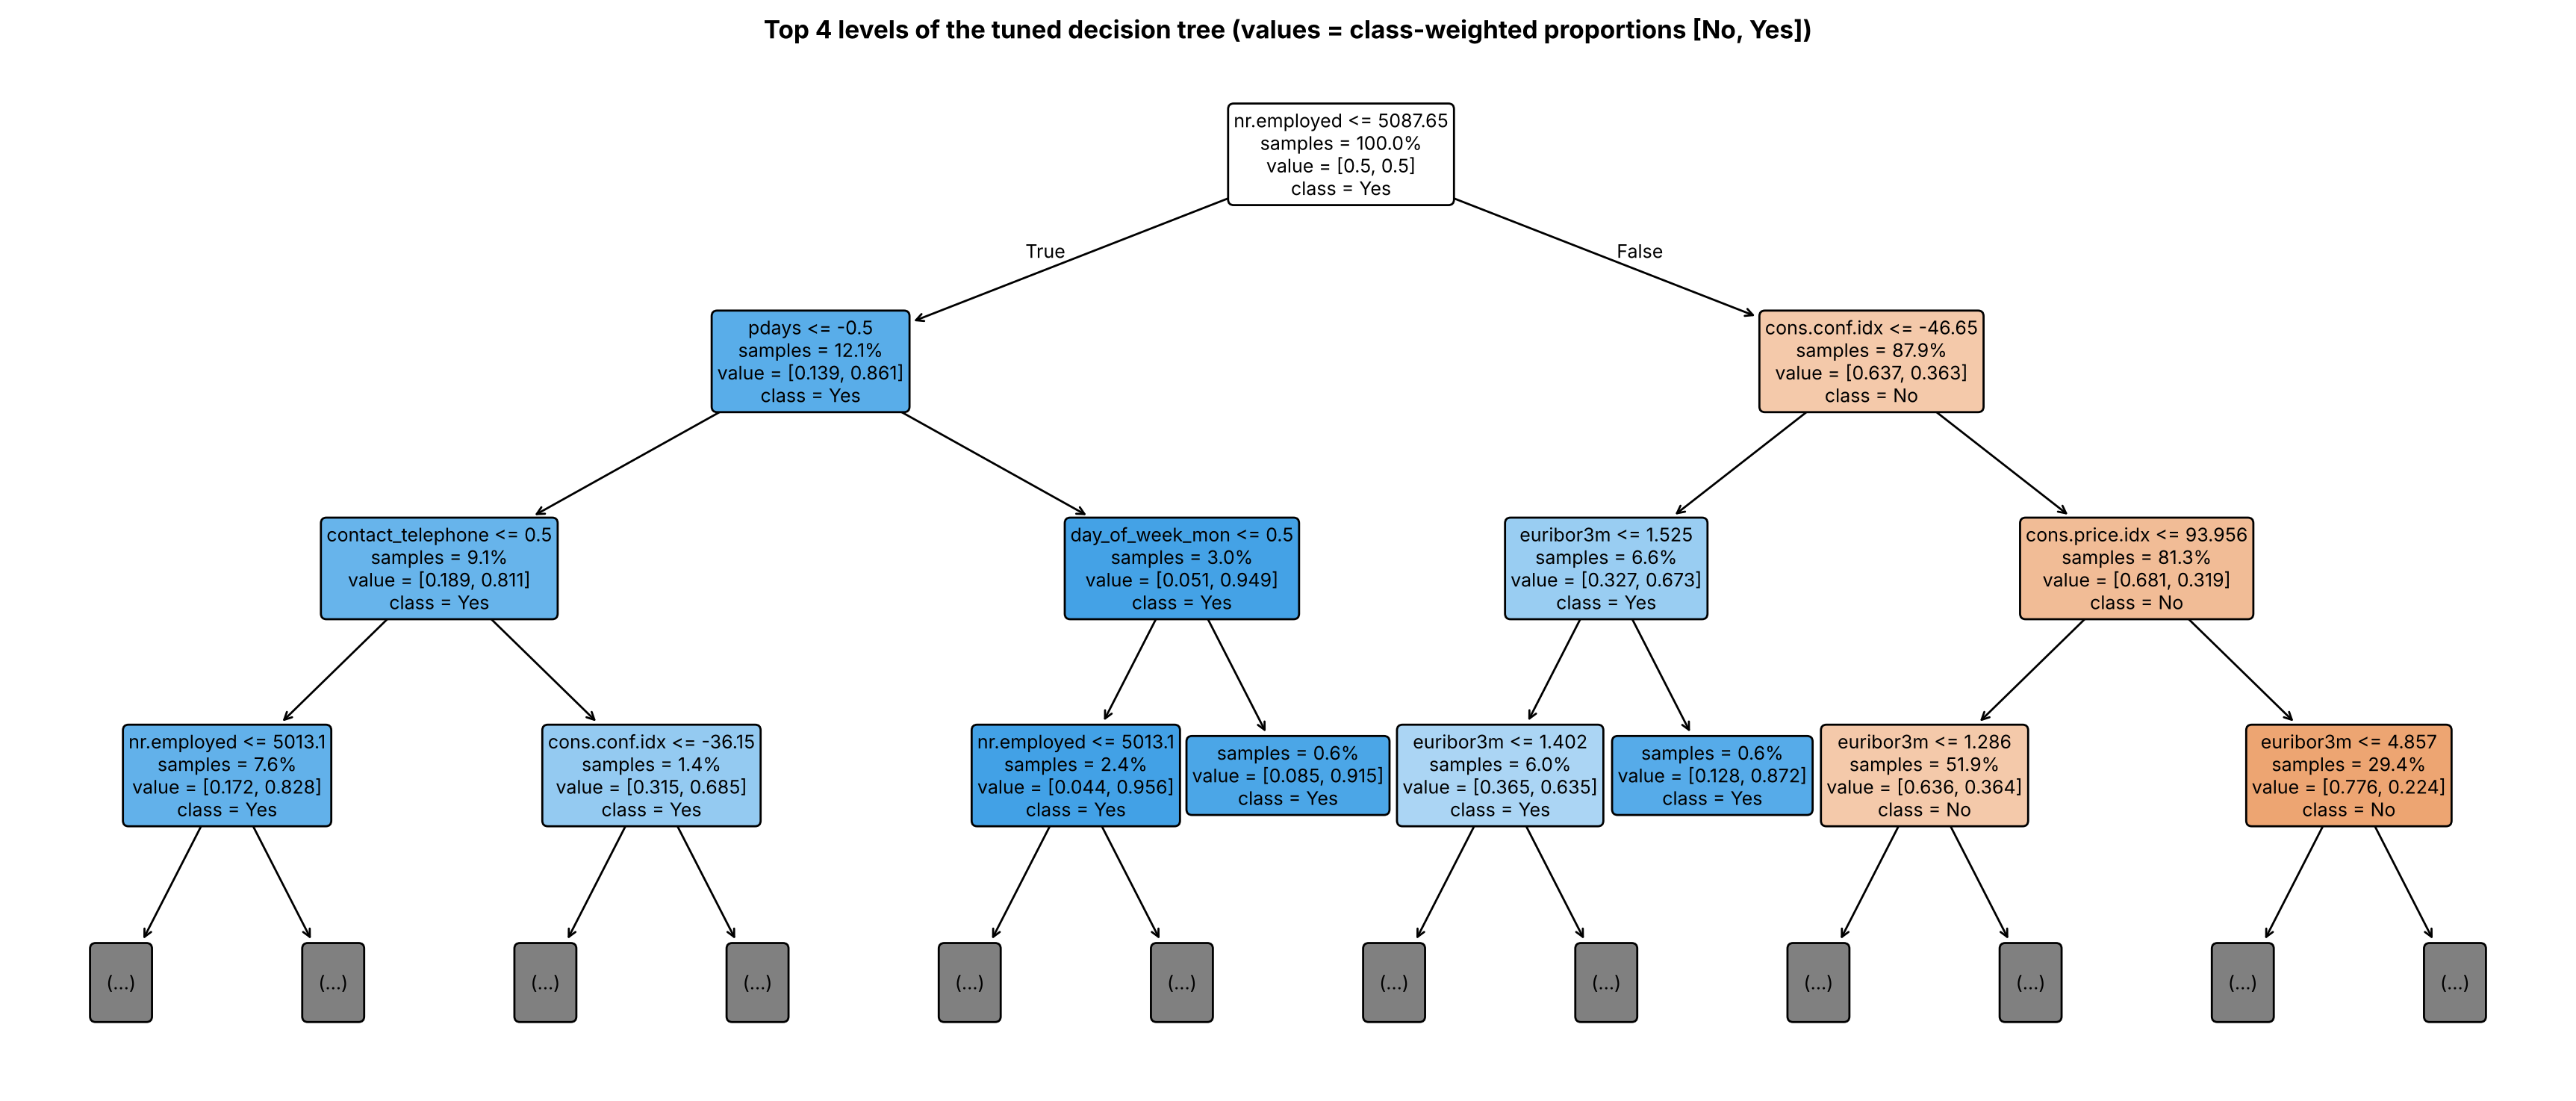

|--- nr.employed <= 5087.65
|   |--- pdays <= -0.50
|   |   |--- contact_telephone <= 0.50
|   |   |   |--- nr.employed <= 5013.10
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- nr.employed >  5013.10
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- contact_telephone >  0.50
|   |   |   |--- cons.conf.idx <= -36.15
|   |   |   |   |--- class: 1
|   |   |   |--- cons.conf.idx >  -36.15
|   |   |   |   |--- class: 1
|   |--- pdays >  -0.50
|   |   |--- day_of_week_mon <= 0.50
|   |   |   |--- nr.employed <= 5013.10
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- nr.employed >  5013.10
|   |   |   |   |--- class: 1
|   |   |--- day_of_week_mon >  0.50
|   |   |   |--- class: 1
|--- nr.employed >  5087.65
|   |--- cons.conf.idx <= -46.65
|   |   |--- euribor3m <= 1.53
|   |   |   |--- euribor3m <= 1.40
|   |   |   |   |--- class: 1
|   |   |   |--- euribor3m >  1.40
|   |   |   |   |--- truncated branch of depth 6
|   |   |--- euribor3m >  

In [13]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(tree, max_depth=3, feature_names=X.columns, class_names=["No", "Yes"],
          filled=True, rounded=True, impurity=False, proportion=True, fontsize=9, ax=ax)
ax.set_title("Top 4 levels of the tuned decision tree (values = class-weighted proportions [No, Yes])")
save(fig, "06_decision_tree")
plt.show()
print(export_text(tree, feature_names=list(X.columns), max_depth=3))

**How to read the tree:** each box is a rule; the left branch means the condition is true. Values are class-weighted (because of `class_weight="balanced"`), so the root shows [0.5, 0.5].

- The top split is `nr.employed <= 5087.65`: calls made when employment was low (the 2009-2010 period) lean strongly towards "yes".
- In that branch, the tree next checks whether the customer was **contacted before** (`pdays`), then the **contact type** (mobile vs landline) and day of week.
- In the high-employment branch (most calls), it relies on consumer confidence, interest rates and prices, which again mostly identify the time period.

These are rules a marketing team can read and check.

## 7. Why `duration` is excluded (data leakage check)

In [14]:
X_leak = pd.get_dummies(df.drop(columns=["y", "age_group"]), drop_first=False).astype(float)
leak = DecisionTreeClassifier(max_depth=tree.get_depth(), min_samples_leaf=tree.min_samples_leaf,
                              class_weight="balanced", random_state=42).fit(X_leak.loc[X_train.index], y_train)
auc_leak = roc_auc_score(y_test, leak.predict_proba(X_leak.loc[X_test.index])[:, 1])
print(f"ROC-AUC without duration: {auc:.3f}")
print(f"ROC-AUC with duration:    {auc_leak:.3f}  <- looks better, but duration is only known after the call")
print(f"Importance of duration in the leaky model: {pd.Series(leak.feature_importances_, X_leak.columns)['duration']:.0%}")

ROC-AUC without duration: 0.804
ROC-AUC with duration:    0.940  <- looks better, but duration is only known after the call
Importance of duration in the leaky model: 53%


## 8. Conclusions

1. The tuned decision tree ranks customers far better than random (see ROC-AUC and the gains chart), using only information available **before** the call.
2. **When** the bank calls matters most: the economic indicators (employment, interest rates) and the month are the strongest predictors. Campaigns worked much better in 2009-2010 than in May 2008.
3. **Who** to call: customers with a successful previous campaign, students and retirees, and people reachable by mobile phone.
4. **How often:** conversion falls with every extra call, so the bank should cap repeated calls to the same person.
5. Including `duration` would raise ROC-AUC a lot but is leakage. Checking for leakage is as important as tuning the model.

**Recommendations:** call customers in the order the model ranks them, focus on past subscribers and mobile numbers, avoid heavy May-style volume campaigns, and stop after 2-3 calls.

## 9. Limitations and next steps

- The economic features mostly encode the **time period**, so the model may not transfer to a different economy without retraining.
- A single tree is easy to read but less accurate than ensembles. Next step: compare with random forest or gradient boosting and calibrate probabilities.
- The data is from one Portuguese bank in 2008-2010.